# Labolatorium 4


## 1. Ustawienia
Ustawienia ustalono przed treningiem. Zbiór testowy służy wyłącznie do końcowej oceny modeli oraz analizy błędu.

In [1]:
import time
import platform

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from IPython.display import display

SEED = 0
DELAY = 8
LENGTHS = (50, 100)
N_TRAIN, N_TEST = 4000, 800
EPOCHS, BATCH, LR = 30, 128, 0.005
DEVICE = torch.device("cpu")
torch.set_num_threads(4)
torch.manual_seed(SEED)
print(f"PyTorch {torch.__version__} | {DEVICE} | {torch.get_num_threads()} wątki")
print(platform.processor() or platform.machine())
print(f"Ziarno {SEED} | trening {N_TRAIN} | test {N_TEST} | "
      f"epoki {EPOCHS} | partia {BATCH} | Adam, lr={LR} | clipping 1.0")

PyTorch 2.14.1+cpu | cpu | 4 wątki
Intel64 Family 6 Model 158 Stepping 9, GenuineIntel
Ziarno 0 | trening 4000 | test 800 | epoki 30 | partia 128 | Adam, lr=0.005 | clipping 1.0


## 2. Dane i ręczna kontrola generatora
Losujemy uporządkowaną parę bez zwracania. Drugi indeks losujemy z zakresu krótszego o jeden i przesuwamy go, gdy wypada na pierwszym indeksie lub za nim. Każda para różnych pozycji ma taką samą szansę wylosowania.

In [2]:
def generate(n, length, rng):
    if length < DELAY + 2:
        raise ValueError("Sekwencja musi pomieścić dwa znaczniki.")
    values = rng.random((n, length), dtype=np.float32)
    count = length - DELAY
    first = rng.integers(count, size=n)
    second = rng.integers(count - 1, size=n)
    second += second >= first
    indicated = np.column_stack((first, second))
    rows = np.arange(n)[:, None]
    markers = np.zeros_like(values)
    markers[rows, indicated + DELAY] = 1
    targets = values[rows, indicated].sum(axis=1, keepdims=True)
    return torch.from_numpy(np.stack((values, markers), axis=-1)), torch.from_numpy(targets)


demo_rng, *data_seeds = np.random.SeedSequence(SEED).spawn(5)
demo_x, demo_y = generate(1, 12, np.random.default_rng(demo_rng))
marker_steps = torch.where(demo_x[0, :, 1] == 1)[0].tolist()
a, b = marker_steps
v1 = demo_x[0, a - DELAY, 0].item()
v2 = demo_x[0, b - DELAY, 0].item()
print(f"Znacznik → próbka: {a+1} → {a+1-DELAY}, {b+1} → {b+1-DELAY}")
print(f"Suma ręczna: {v1:.9f} + {v2:.9f} = {v1+v2:.9f}")
print(f"Cel generatora: {demo_y.item():.9f}")
assert np.isclose(v1 + v2, demo_y.item())

datasets = {}
for i, length in enumerate(LENGTHS):
    train = generate(N_TRAIN, length, np.random.default_rng(data_seeds[2*i]))
    test = generate(N_TEST, length, np.random.default_rng(data_seeds[2*i+1]))
    for x, y in (train, test):
        assert torch.all(x[:, :, 1].sum(dim=1) == 2)
        assert torch.all(x[:, :DELAY, 1] == 0)
        reconstructed = (x[:, DELAY:, 1] * x[:, :-DELAY, 0]).sum(dim=1, keepdim=True)
        torch.testing.assert_close(y, reconstructed, rtol=0, atol=0)
    datasets[length] = (train, test)

Znacznik → próbka: 9 → 1, 12 → 4
Suma ręczna: 0.802237868 + 0.316337109 = 1.118574977
Cel generatora: 1.118574977


## 3. Architektury
Sieci rekurencyjne mają jedną warstwę i odczyt liniowy z ostatniego kroku. Conv1D ma trzy warstwy z ReLU, krok 1 i odczyt liniowy ze średniej mapy cech po czasie.

In [3]:
class RNNNet(nn.Module):
    def __init__(self, kind, hidden=32):
        super().__init__()
        layer = {"SimpleRNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        self.rnn = layer(2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


class ConvNet(nn.Module):
    def __init__(self, channels=32, dilations=(1, 2, 4)):
        super().__init__()
        layers = []
        in_channels = 2
        for dilation in dilations:
            layers.extend([
                nn.Conv1d(in_channels, channels, kernel_size=3, stride=1,
                          padding=dilation, dilation=dilation),
                nn.ReLU(),
            ])
            in_channels = channels
        self.net = nn.Sequential(*layers)
        self.fc = nn.Linear(channels, 1)

    def forward(self, x):
        return self.fc(self.net(x.transpose(1, 2)).mean(dim=2))


for dilations in [(1, 2, 4), (1, 1, 1)]:
    field = 1 + 2 * sum(dilations)
    model = ConvNet(dilations=dilations)
    features = model.net(torch.zeros(1, 2, 100))
    assert features.shape == (1, 32, 100)
    print(f"Dylatacje {dilations} | pole {field} | "
          f"wspólne okno dla pary: {'tak' if field > DELAY else 'nie'}")

Dylatacje (1, 2, 4) | pole 15 | wspólne okno dla pary: tak
Dylatacje (1, 1, 1) | pole 7 | wspólne okno dla pary: nie


## 4. Uczenie i końcowa ocena
Dla danego L funkcja dostaje gotowe, wspólne tensory. Każdy przebieg używa tej samej kolejności partii. Pomiar obejmuje pętlę treningową z losowaniem partii i aktualizacją wag. Ocena testowa odbywa się po zatrzymaniu zegara.

In [4]:
def fit(model, train, test):
    model = model.to(DEVICE)
    x_train, y_train = (t.to(DEVICE) for t in train)
    x_test, y_test = (t.to(DEVICE) for t in test)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.MSELoss()
    order_rng = torch.Generator().manual_seed(SEED)
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    start = time.perf_counter()
    for _ in range(EPOCHS):
        model.train()
        order = torch.randperm(len(x_train), generator=order_rng)
        for idx in order.split(BATCH):
            optimizer.zero_grad(set_to_none=True)
            criterion(model(x_train[idx]), y_train[idx]).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
    seconds = time.perf_counter() - start

    model.eval()
    with torch.inference_mode():
        predictions = torch.cat([model(x) for x in x_test.split(BATCH)])
        mse = criterion(predictions, y_test).item()
    return mse, seconds, params, predictions.cpu()


base_names = ("SimpleRNN", "LSTM", "GRU", "Conv1D")
results, baselines, predictions = {}, {}, {}
for length, (train, test) in datasets.items():
    constant = train[1].mean().item()
    baseline = (test[1] - constant).square().mean().item()
    baselines[length] = (constant, baseline)
    print(f"L={length}: średnia treningowa {constant:.6f}, test MSE stałej {baseline:.6f}")
    names = base_names if length == 50 else (*base_names, "SimpleRNN h=64", "Conv1D [1,1,1]")
    for name in names:
        torch.manual_seed(SEED)
        if name.startswith("Conv1D"):
            model = ConvNet(dilations=(1, 1, 1) if name.endswith("]") else (1, 2, 4))
        elif name == "SimpleRNN h=64":
            model = RNNNet("SimpleRNN", hidden=64)
        else:
            model = RNNNet(name)
        mse, seconds, params, pred = fit(model, train, test)
        results[length, name] = (mse, seconds, params)
        predictions[length, name] = pred
        print(f"  {name:15s}  MSE {mse:.6f}  czas {seconds:7.2f} s  parametry {params}", flush=True)

L=50: średnia treningowa 1.006803, test MSE stałej 0.171521
  SimpleRNN        MSE 0.174312  czas   12.47 s  parametry 1185
  LSTM             MSE 0.174669  czas   12.93 s  parametry 4641
  GRU              MSE 0.159929  czas   28.19 s  parametry 3489
  Conv1D           MSE 0.169184  czas   10.69 s  parametry 6465
L=100: średnia treningowa 1.001284, test MSE stałej 0.163515
  SimpleRNN        MSE 0.165007  czas   24.44 s  parametry 1185
  LSTM             MSE 0.163122  czas   16.31 s  parametry 4641
  GRU              MSE 0.160465  czas   54.55 s  parametry 3489
  Conv1D           MSE 0.162520  czas   12.33 s  parametry 6465
  SimpleRNN h=64   MSE 0.164388  czas   21.30 s  parametry 4417
  Conv1D [1,1,1]   MSE 0.162605  czas   16.41 s  parametry 6465


## 5. Zmiana test MSE wraz z długością sekwencji

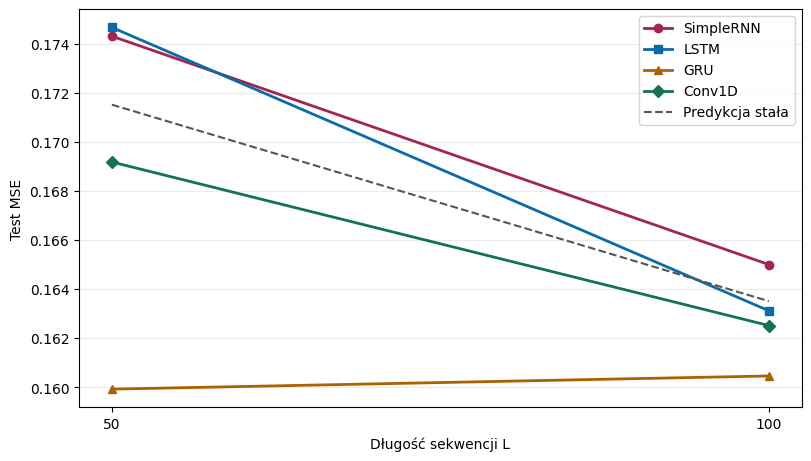

In [5]:
fig, ax = plt.subplots(figsize=(8.0, 4.5), layout="constrained")
for name, color, marker in zip(base_names, ["#a42550", "#096ba9", "#ad6200", "#137351"], ["o", "s", "^", "D"]):
    ax.plot(LENGTHS, [results[length, name][0] for length in LENGTHS],
            marker=marker, linewidth=2, label=name, color=color)
ax.plot(LENGTHS, [baselines[length][1] for length in LENGTHS],
        "--", color="#555555", label="Predykcja stała")
ax.set(xlabel="Długość sekwencji L", ylabel="Test MSE", xticks=LENGTHS)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="best")
display(fig)
plt.close(fig)

## 6. Przykład z dużym błędem
Wybieramy największy błąd kwadratowy SimpleRNN dla L = 100, z wariantu podstawowego.

In [6]:
length, name = 100, "SimpleRNN"
x_test, y_test = datasets[length][1]
pred = predictions[length, name]
index = int((pred - y_test).square().argmax())
marker_idx = torch.where(x_test[index, :, 1] == 1)[0]
value_idx = marker_idx - DELAY
sample_values = x_test[index, value_idx, 0].tolist()
target, estimate = y_test[index].item(), pred[index].item()
print(f"Próbka testowa nr {index+1}")
for t, s, value in zip(marker_idx.tolist(), value_idx.tolist(), sample_values):
    print(f"Znacznik {t+1} → próbka {s+1}: {value:.9f}")
print(f"Cel {target:.9f} | predykcja {estimate:.9f} | błąd bezwzględny {abs(target-estimate):.9f}")
print(f"Kroki od ostatniego znacznika do odczytu: {length-1-int(marker_idx[-1])}")

Próbka testowa nr 436
Znacznik 71 → próbka 63: 0.939668894
Znacznik 93 → próbka 85: 0.988698900
Cel 1.928367853 | predykcja 0.955031753 | błąd bezwzględny 0.973336101
Kroki od ostatniego znacznika do odczytu: 7
